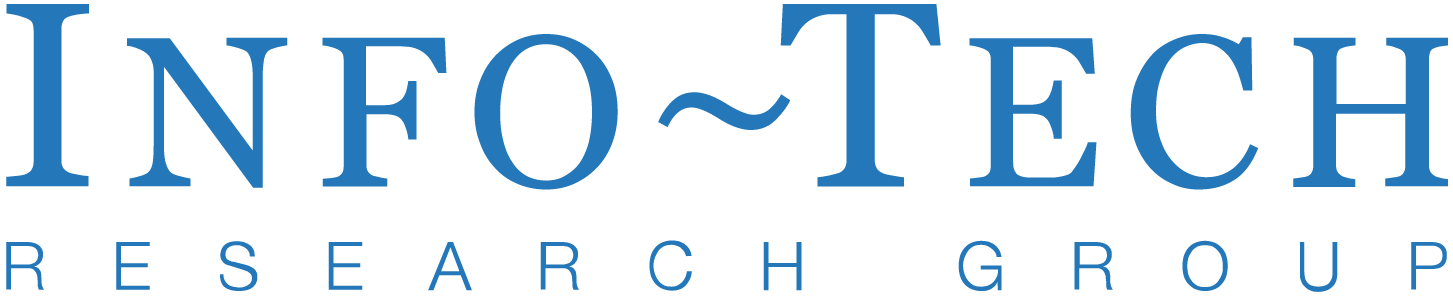

# **Licensing and Proprietary Information Notice**

This notebook is for **Educational purposes** only.

By using this notebook, users agree to respect the intellectual property rights of InfoTech Research Group and to use the provided content and technology in accordance with all applicable laws and regulations.

By uploading any data to the notebook User agrees that uploads will not:

- Include misrepresentative, obscene, libelous, defamatory, threatening, harassing, abusive, hateful, sexually explicit, sexually oriented, profane or embarrassing material, as determined by Info-Tech in its sole discretion;

- Be otherwise objectionable.

### **Limitation of Liability**

> InfoTech disclaims all liability for any actions taken by users outside the educational scope of this course involving the use of this Google Colab notebook. Info-Tech is not liable for any technical issues resulting from use of the Google Colab notebook and User must resolve any technical issues with Google Colab. Should you choose to download this notebook and apply its contents for personal or other uses, you accept full responsibility for any outcomes that arise. InfoTech is not responsible for any direct, indirect, incidental, or consequential damages that may result from such use.


In [ ]:
#@markdown Credits to: Ultralytics and https://github.com/AssemblyAI-Examples/mediapipe-python

#@markdown ``` @software{yolov8_ultralytics, ```
#@markdown ``` author = {Glenn Jocher and Ayush Chaurasia and Jing Qiu},```
#@markdown ``` title = {Ultralytics YOLOv8},```
#@markdown ``` version = {8.0.0},```
#@markdown ``` year = {2023},```
#@markdown ``` url = {https://github.com/ultralytics/ultralytics},```
#@markdown ``` orcid = {0000-0001-5950-6979, 0000-0002-7603-6750, 0000-0003-3783-7069},```
#@markdown ``` license = {AGPL-3.0} ```
#@markdown ``` } ```


---



---



# How to use this Notebook

If you do not see any sort of GPU:

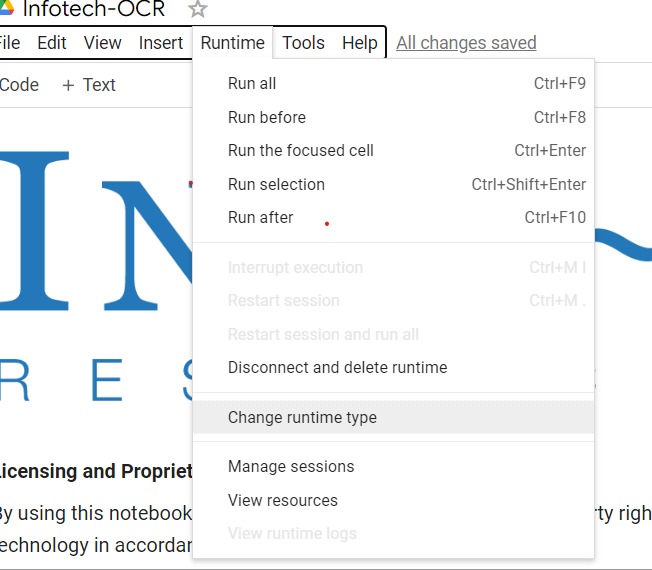

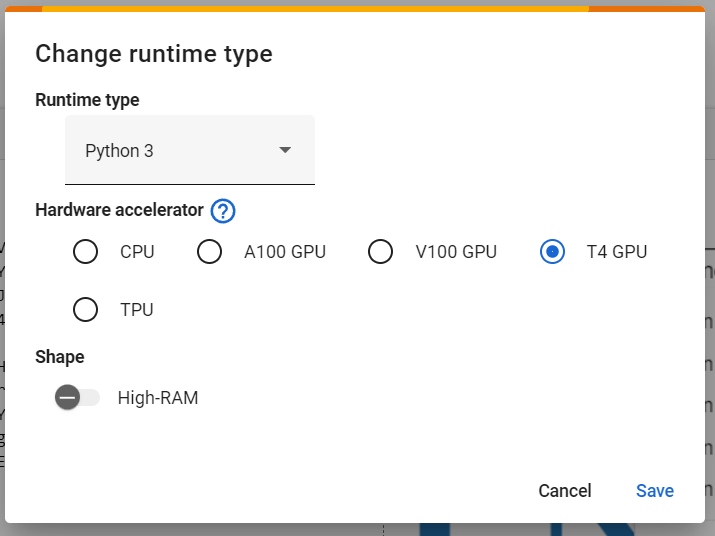

Click the "Connect" button.
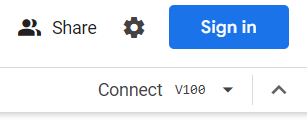


Then Hit the "Play" Button on each cell.

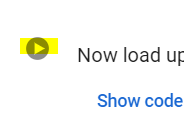

# Software Setup 🔧

In [1]:
%%capture
#@title Installing required libraries and downloading data.
#@markdown This section will install necessary libraries and setup the environment.

#@markdown Press ▶
!pip install keras-ocr
!pip install tensorflow
!pip install numpy
!pip install PyQt5
!pip install ipython
!pip install ffmpeg-python
!pip install ultralytics
!pip install lapx
!pip install gdown

import gdown
import os

!gdown --id 1RKJ0_vsqLsaJSYuYGm2ppunuSEMz-qvQ # dog park
!gdown --id 1h4YX1dgqEfJLfEcZb3Ku7Llwq7Zp5O1G # woman
!gdown --id 1dWqbacszWFyGTN04eDorZ59KIABYTGvI # man pose
!gdown --id 1p4IxZp2gYQ8DirvWhAUXt7vdUHvYAZQL # soccer
!gdown --id 18penwqEFSVrEVQcETDzCAix0o6e2MIry # newyork
!gdown --id 1QLc0F6TQzNTc39AT-s3fjMe8zDE9wLmL # ocr1
!gdown --id 11aKm8WYW2dMzKgJX3t6pTmgMB3JQG0Ii # ocr2
!gdown --id 1Hm2EvZekDm9pKkixh0rc7w29SaL0vWry # ocr 3
!gdown --id 1WDi0PRhkG9qmKBMR_on0TF2y887ahWlG # ocr 4
!gdown --id 1rLIgZSjPT609BDyoukaOUdAMhetWohLx #newyork seg
!gdown --id 1h0Oy95exxg8zd5DsVtWxhA2BSUk3FLcp # man pose rotation
!gdown --id 1SVtJYsqnDTFXp5f-3JtTbC3thYyN9fLG # messi


In [2]:
#@title Importing necessary libraries and setting up utilities.

#@markdown Press ▶
%%capture
import cv2
import urllib.request
import numpy as np
import pickle
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import animation
import PyQt5
from PIL import Image
from IPython.display import HTML
import importlib
from base64 import b64encode
from ultralytics import YOLO

#%matplotlib qt
%matplotlib inline



# Load a model from ultralytics
model_classification = YOLO('yolov8n-cls.pt')
model_objectdet = YOLO('yolov8n.pt')
model_segmentation = YOLO('yolov8n-seg.pt')
model_pose = YOLO('yolov8n-pose.pt')

lmscode = "2iQz2AioT5MqVEX9"
key = {
    "1": "3",
    "2": "3",
    "3": "1",
    "4": "1",
    "5": "2",
}

user_answers = {}

url = [
    "ocr_1.png",
    "ocr_2.png",
    "ocr_3.png",
    "ocr_4.png",
]

# Credit to functions from https://github.com/AssemblyAI-Examples/mediapipe-python
def scale_axes(ax):
    # Scale axes properly
    # https://stackoverflow.com/questions/13685386/matplotlib-equal-unit-length-with-equal-aspect-ratio-z-axis-is-not-equal-to
    x_limits = ax.get_xlim3d()
    y_limits = ax.get_ylim3d()
    z_limits = ax.get_zlim3d()

    x_range = abs(x_limits[1] - x_limits[0])
    x_middle = np.mean(x_limits)
    y_range = abs(y_limits[1] - y_limits[0])
    y_middle = np.mean(y_limits)
    z_range = abs(z_limits[1] - z_limits[0])
    z_middle = np.mean(z_limits)

    # The plot bounding box is a sphere in the sense of the infinity
    # norm, hence I call half the max range the plot radius.
    plot_radius = 0.5 * max([x_range, y_range, z_range])

    ax.set_xlim3d([x_middle - plot_radius, x_middle + plot_radius])
    ax.set_ylim3d([y_middle - plot_radius, y_middle + plot_radius])
    ax.set_zlim3d([z_middle - plot_radius, z_middle + plot_radius])

    ax.axes.xaxis.set_ticklabels([])
    ax.axes.yaxis.set_ticklabels([])
    ax.axes.zaxis.set_ticklabels([])
    ax.axes.xaxis.set_ticks([])
    ax.axes.yaxis.set_ticks([])
    ax.axes.zaxis.set_ticks([])


# Function to check answers and calculate score
def grade(user_answers, key):
    correct_answers_count = 0
    unanswered_questions = []
    final_score = 0
    is_perfect = False  # Initialize the perfection flag as False

    for question, correct_answer in key.items():
        user_answer = user_answers.get(question)
        if user_answer is None:
            unanswered_questions.append(question)  # Collecting unanswered questions
            continue  # Skip further processing for this iteration

        if user_answer == correct_answer:
            print(f"Question {question}: Correct!")
            correct_answers_count += 1
        else:
            #print(f"Question {question}: Incorrect! The answer is {correct_answer}")
            print(f"Question {question}: Incorrect!")

    total_questions = len(key)
    if unanswered_questions:
        print("You have not answered all the questions. Please complete the following questions before getting your final grade:")
        print(", ".join(unanswered_questions))
    else:
        # Calculate and print final score if all questions are answered
        final_score = correct_answers_count / total_questions * 100  # Final score as a percentage
        is_perfect = correct_answers_count == total_questions  # Set perfection flag based on score
        print("--------------------------------------------------------------------------")
        print(f"Final Score: {final_score}% ({correct_answers_count} out of {total_questions} correct)")
        print("--------------------------------------------------------------------------")

    return final_score, is_perfect


# Foundational Knowledge 📚

## **Brief History of Computer Vision**

The field of computer vision seeks to replicate the human visual system, allowing computers to see and interpret the world. Its inception dates back to the 1960s, when early experiments, such as attempting to enable computers to recognize simple patterns and shapes, laid the groundwork for modern computer vision. Since then, the field has evolved significantly, particularly with the advent of deep learning, leading to advancements in image recognition, object detection, and beyond.

\
## **Industrial Applications of Computer Vision**

Computer vision technology has been adopted across various industries, demonstrating its ability to enhance efficiency, accuracy, and decision-making. Some notable applications include:

- **Healthcare**: From diagnosing diseases through medical imaging to assisting in surgeries by providing real-time insights.

- **Automotive**: Enabling autonomous vehicles to navigate by recognizing traffic signs, pedestrians, and other vehicles.

- **Retail**: Streamlining inventory management, enhancing customer experience through behavior analysis, and enabling automated checkouts.
Manufacturing: Assisting in quality control by identifying defects and optimizing manufacturing processes.

- **Security**: Enhancing surveillance systems through facial recognition and anomaly detection.

\
## **Major Topics in Computer Vision**

Computer vision tasks are often categorized into two primary areas: human-centric and world-centric.

**Human-centric Vision Tasks** involve understanding human beings from visual data. This includes analyzing facial features, estimating body poses, recognizing gestures, and interpreting emotions. These tasks aim to enable machines to interact with and understand humans in various contexts.

**World-centric Vision Tasks** focus on identifying and understanding objects and scenes in the environment. This includes classifying images, detecting and locating objects, segmenting images into meaningful parts,  and Optical Character Recognition (OCR) for converting images of text into editable and searchable data.These tasks are fundamental to applications that require interaction with or navigation through the physical world.

\
## **Algorithms and Use Cases**

**Human-centric Algorithms:**

- **Facial Analysis**: Techniques like Deep Convolutional Neural Networks (DCNNs) are used for facial recognition, emotion detection, and attribute analysis. Use cases include security systems for identity verification and marketing strategies based on emotion recognition.

- **Pose Estimation**: Algorithms such as OpenPose and Convolutional Pose Machines (CPMs) identify human figures in images or videos and estimate their posture. Applications range from sports analytics and physical therapy to interactive gaming.

\
## **World-centric Algorithms:**

- **Classification**: Convolutional Neural Networks (CNNs) categorize images into predefined classes, critical for organizing large image databases and enhancing search engine capabilities.

- **Object Detection:** Techniques like YOLO (You Only Look Once) and SSD (Single Shot Detector) aim to identify and locate multiple objects within an image, crucial for applications like surveillance and autonomous navigation.

- **Segmentation**: Methods such as Fully Convolutional Networks (FCNs) and U-Net are used for detailed image analysis, separating objects at the pixel level for applications in medical imaging, autonomous driving, and agricultural monitoring.

- **Optical Character Recognition (OCR)**: OCR technology is crucial for digitizing printed documents and automating data entry, involving image pre-processing, text detection, character recognition, and post-processing to improve accuracy.
    1. Template-Based OCR: This type involves matching document templates or forms against a set of predefined templates to extract text. It's particularly useful for structured documents commonly found in supply chains, like invoices and shipping forms.
    2. Intelligent Character Recognition (ICR): ICR goes beyond traditional OCR by recognizing and learning different handwriting styles. In supply chains, it can be applied to handwritten notes on packages or custom declarations.
    3. Optical Mark Recognition (OMR): OMR is used for detecting marks rather than text. It's beneficial for processing checklists or inventory sheets where items are often marked manually.


These algorithms represent the cutting edge of computer vision, enabling a wide range of applications that mimic and extend human visual capabilities. Through this lab, we'll explore these algorithms' applications, focusing on the transformative potential of computer vision in various domains.

\
## **AI Libraries and Deployment:**

When developing computer vision applications, the choice of AI libraries is crucial depending on the specific requirements and complexity of the task:

- **OpenCV**: Ideal for foundational computer vision tasks such as image editing, preprocessing, and basic algorithms for object tracking, edge detection, and facial recognition. OpenCV is optimized for real-time applications and is widely used for its robust performance in handling visual data manipulation without the complexities of deep learning.


- **PyTorch and TensorFlow**: These libraries are better suited for deep learning solutions. They offer extensive support for deep learning models, including a range of pre-trained models and environments for custom model training. These frameworks are particularly powerful for developing sophisticated computer vision applications involving object detection, image classification, and more.

\
## **Deployment Considerations:**
Deployment of these models can vary based on the application's requirements:
- **CPUs** are most cost-efficient and are generally sufficient for less complex models or low-throughput tasks.
- **GPUs** provide significant speed and efficiency in training and inference, making them ideal for more complex models that require intensive computations.
- **TPUs** are used for large-scale deployments and are known for providing faster processing times and handling substantial datasets effectively.


# Application 🍳

## World-Centric Computer Vision

> ❗ **DISCLAIMER**: All static images seen in Classification/Object Detection/Segmentation/Human Pose examples below have been created using Generative AI and are property of Info-Tech Research Group.

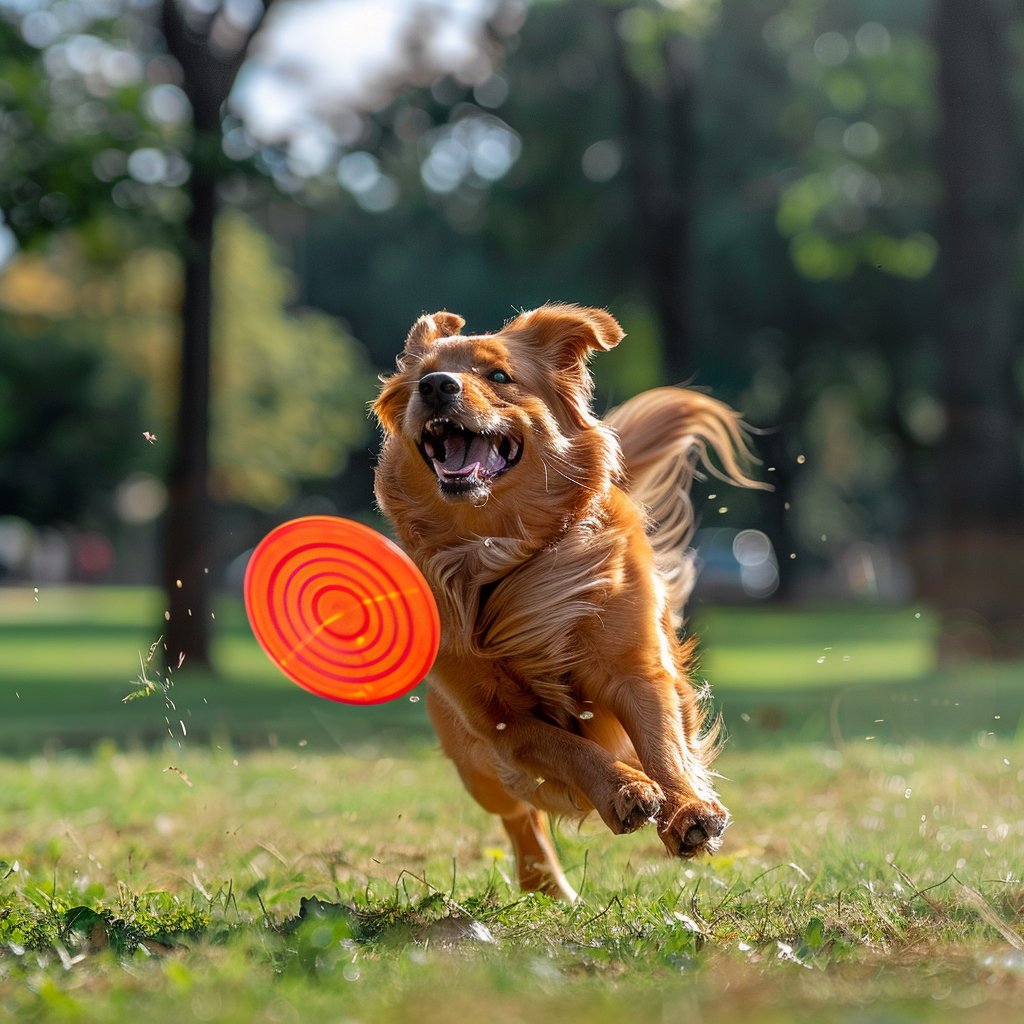

In [ ]:
#@title Image #1: Dog at the Park

#@markdown Press ▶ on the cell to take a look at the image we will work with for the following cells.
#@markdown > ❗ **DISCLAIMER**: The following image below has been created using Generative AI and is property of Info-Tech Research Group.

display(Image.open('dog_park.png'))

In [ ]:
#@title Classification

#@markdown This cell uses a deep learning model for image classification. Classification algorithms categorize images into predefined classes based on their content. When you run this cell, the model will predict the category of objects present in the input image.

#@markdown The output will include the original image annotated with labels indicating the predicted classes along with their confidence scores. This visualization helps understand how the model perceives different elements within the image.

#@markdown **Common Use Cases:** Image classification is used in various applications such as sorting images in photo libraries, content moderation on social media platforms, and retail product categorization.

#@markdown Press ▶

# Predict with the model
results = model_classification("dog_park.png", verbose=False)  # predict on an image

# Process results list
for result in results:
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    result.save(filename='classification_result.jpg')  # save to disk

display(Image.open('classification_result.jpg'))

error: OpenCV(4.11.0) :-1: error: (-5:Bad argument) in function 'imdecode'
> Overload resolution failed:
>  - buf is not a numpy array, neither a scalar
>  - Expected Ptr<cv::UMat> for argument 'buf'


In [ ]:
#@title Object Detection

#@markdown This cell utilizes an object detection model to identify and locate objects within an image. Object detection algorithms aim to determine what objects are present in an image and where they are situated by drawing bounding boxes around them.

#@markdown Upon execution, you will see the input image with bounding boxes around detected objects, each box labeled with the object's name and the model's confidence in its prediction. This output illustrates the model's ability to not only recognize objects but also determine their position and size relative to the image frame.

#@markdown **Common Use Cases:** Object detection is crucial for surveillance systems, traffic management, counting objects in scenes, and retail object tracking for inventory management.

#@markdown Press ▶

# Predict with the model
results = model_objectdet("dog_park.png", verbose=False)  # predict on an image

# Process results list
for result in results:
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    result.save(filename='objectdetection_result.jpg')  # save to disk

display(Image.open('objectdetection_result.jpg'))

In [ ]:
#@title Segmentation

#@markdown This cell applies a segmentation model to the input image. Segmentation algorithms partition the image into multiple segments or pixels, each corresponding to different objects or regions. This detailed analysis allows for a granular understanding of the image composition.

#@markdown The output will display the original image overlaid with color-coded masks indicating different segments identified by the model. This helps visualize how the model differentiates between various elements within the image, down to the pixel level.

#@markdown **Common Use Cases:** Image segmentation is widely used in medical imaging for tumor detection, autonomous vehicles for road and obstacle detection, and in agriculture for crop and weed identification.

#@markdown Press ▶

# Predict with the model
results = model_segmentation("dog_park.png", verbose=False)  # predict on an image

# Process results list
for result in results:
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    result.save(filename='segmentation_result.jpg')  # save to disk

display(Image.open('segmentation_result.jpg'))

In [ ]:
#@title Use Case: Live Segmentation

#@markdown Let's do some live instance segementation in New York! This is something Autonomous vehicles do on a daily basis.

#@markdown Press ▶ to start.

#@markdown This may take a few moments while it processes. Hang tight!

# check if newyork_seg_compressed.mp4 is here
if not os.path.exists("newyork_seg_compressed.mp4"):

    import cv2
    from ultralytics import YOLO
    from ultralytics.utils.plotting import Annotator, colors

    model_segmentation = YOLO("yolov8n-seg.pt")  # segmentation model
    names = model_segmentation.model.names
    cap = cv2.VideoCapture("newyork.mp4")
    w, h, fps = (int(cap.get(x)) for x in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT, cv2.CAP_PROP_FPS))

    out = cv2.VideoWriter('newyork_seg.mp4', cv2.VideoWriter_fourcc(*'MJPG'), fps, (w, h))

    print("Starting video processing...")
    frame_id = 0
    while True:
        frame_id += 1

        ret, im0 = cap.read()

        if not ret:
            print("Video processing has been successfully completed.")
            break

        results = model_segmentation.predict(im0, verbose=False)
        annotator = Annotator(im0, line_width=2)

        if results[0].masks is not None:
            clss = results[0].boxes.cls.cpu().tolist()
            masks = results[0].masks.xy

            for mask, cls in zip(masks, clss):
                annotator.seg_bbox(mask=mask,
                                mask_color=colors(int(cls), True),
                                det_label=names[int(cls)])

        out.write(im0)

    out.release()
    cap.release()
    cv2.destroyAllWindows()

    print("Creating final video...")
    os.system("ffmpeg -i newyork.mp4 -i newyork_seg.mp4 -filter_complex '[0:v]scale=-1:720[left];[1:v]scale=-1:720[right];[left][right]hstack=inputs=2[v]' -map '[v]' -c:v libx264 newyork_stitched.mp4 -y")

    print("Compressing final video...")
    os.system(f"ffmpeg -i newyork_stitched.mp4 -vcodec libx264 newyork_seg_compressed.mp4 -y")

mp4 = open("newyork_seg_compressed.mp4",'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=1500 controls loop autoplay>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

## Human-Centric Computer vision

In [ ]:
#@title Image #2: Human Body

#@markdown Press ▶ on the cell to take a look at the image we will work with for the following cells.
#@markdown > ❗ **DISCLAIMER**: The following image below has been created using Generative AI and is property of Info-Tech Research Group.

display(Image.open('man_pose.png'))

In [ ]:
#@title Pose Wireframe

#@markdown This cell applies pose estimation to analyze the posture and positioning of humans in the provided image. Pose estimation models identify key points on the body such as elbows, knees, wrists, and shoulders to understand human body postures.

#@markdown When executed, you will observe the original image with key points and skeletal structure superimposed, illustrating the pose of the person. This output helps in analyzing body language, movement, and engagements in various activities.

#@markdown **Common Use Cases:** Pose estimation is widely used in sports analytics for performance improvement, in health and fitness apps to correct exercises, in surveillance for activity recognition, and in gaming for motion-based controls.


import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import mediapipe as mp

mp_pose = mp.solutions.pose
mp_drawing = mp.solutions.drawing_utils
mp_drawing_styles = mp.solutions.drawing_styles

file_name = 'man_pose.png'
original_img = Image.open(file_name)

# Create a MediaPipe `Pose` object
with mp_pose.Pose(static_image_mode=True,
                  model_complexity=2,
                  enable_segmentation=True) as pose:

    # Read the file in and get dimensions
    image = cv2.imread(file_name)

    # Convert the BGR image to RGB and then process with the `Pose` object
    results = pose.process(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

# Copy the image for drawing
annotated_image = image.copy()

# Draw pose landmarks on the copied image
mp_drawing.draw_landmarks(annotated_image,
                          results.pose_landmarks,
                          mp_pose.POSE_CONNECTIONS,
                          landmark_drawing_spec=mp_drawing_styles.get_default_pose_landmarks_style())

# Generate the pose wireframe image
pose_wireframe_img = Image.fromarray(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))

# Create the green screen effect
segmented_image = image.copy()
tightness = .3  # Tightness for the segmentation

# Apply segmentation condition
condition = np.stack((results.segmentation_mask,) * 3, axis=-1) > tightness
bg_image = np.zeros(image.shape, dtype=np.uint8)
bg_image[:] = [4, 244, 4]  # Green background

# Combine original image and background based on condition
segmented_image = np.where(condition, segmented_image, bg_image)
pose_green_screen_img = Image.fromarray(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))

# Display images side by side
fig, axs = plt.subplots(1, 3, figsize=(30, 15))
axs[0].imshow(original_img)
axs[0].set_title('Original Image')
axs[0].axis('off')

axs[1].imshow(pose_wireframe_img)
axs[1].set_title('Pose Wireframe')
axs[1].axis('off')

axs[2].imshow(pose_green_screen_img)
axs[2].set_title('Pose Green Screen')
axs[2].axis('off')

plt.show()


In [ ]:
#@title 3D Pose View

#@markdown Let's see how his pose could be estimated in 3D space!

#@markdown Press ▶ to start.

#@markdown This may take a few moments while it processes. Hang tight!

if not os.path.exists("pose_rotation.mp4"):

    # Pickle data as numpy array
    data = np.empty((3, len(mp_holistic.PoseLandmark)))

    landmarks = results.pose_world_landmarks.landmark
    for i in range(len(mp_holistic.PoseLandmark)):
        data[:, i] = (landmarks[i].x, landmarks[i].y, landmarks[i].z)

    fig = plt.figure()
    fig.set_size_inches(5, 5, True)
    ax = fig.add_subplot(projection='3d')

    plot_data(data, ax)
    scale_axes(ax)

    filename = 'pose_rotation.mp4'
    rotate_and_save(fig, ax, filename, save=True)

mp4 = open("pose_rotation.mp4",'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML("""
<video width=800 controls loop autoplay>
      <source src="%s" type="video/mp4">
</video>
""" % data_url)

In [ ]:
#@title 3D pose estimation on Live Video

#@markdown This cell performs 3D pose estimation on video content, extending the principles of pose estimation to three dimensions. This allows for a more detailed analysis of human movement and behavior over time, capturing the depth and dynamics of body postures.

#@markdown Upon execution, you will view a video with 3D pose annotations overlaid on the subjects, providing insights into their movements and interactions. This enhanced visualization is particularly useful for detailed movement analysis and interactive applications.

#@markdown **Common Use Cases:** 3D pose estimation is crucial in professional sports training, advanced physical therapy, virtual reality (VR) content creation, and animation for creating lifelike movements in digital characters.

#@markdown Press ▶ to start.

#@markdown This may take a few moments while it processes. Hang tight!

if not os.path.exists("messi.mp4"):

    import os
    # Initialize MediaPipe Pose
    mp_pose = mp.solutions.pose
    pose = mp_pose.Pose(min_detection_confidence=0.5, min_tracking_confidence=0.5)

    # File paths
    input_file = "soccer.mp4"
    pose_overlayed_file = "pose_overlayed_video.mp4"
    wireframe_file = "walking_wireframe.mp4"
    final_stitched_file = "final_output.mp4"
    final_compressed_file = "messi.mp4"

    # Open input video
    cap = cv2.VideoCapture(input_file)

    if not cap.isOpened():
        print("Error opening video stream or file")
        raise TypeError

    # Prepare Video Writer
    fourcc = cv2.VideoWriter_fourcc(*'MP4V')
    out_fps = 30.0
    out_size = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    out = cv2.VideoWriter(pose_overlayed_file, fourcc, out_fps, out_size)

    # Initialize data array for wireframe animation
    length = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    data = np.zeros((3, len(mp_pose.PoseLandmark), length))

    print("Detecting live pose...")
    frame_num = 0
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        # Process the pose and draw
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = pose.process(frame_rgb)

        # Draw the pose annotation on the frame.
        annotated_image = frame.copy()
        mp.solutions.drawing_utils.draw_landmarks(
            annotated_image, results.pose_landmarks, mp.solutions.pose.POSE_CONNECTIONS)

        # Collect data for wireframe animation
        if results.pose_world_landmarks is not None:
            landmarks = results.pose_world_landmarks.landmark
            for i in range(len(mp_pose.PoseLandmark)):
                data[:, i, frame_num] = (landmarks[i].x, landmarks[i].y, landmarks[i].z)

        out.write(annotated_image)
        frame_num += 1

    cap.release()
    out.release()

    print("Creating wireframe...")
    # Wireframe Animation
    fig = plt.figure()
    fig.set_size_inches(5, 5, True)
    ax = fig.add_subplot(projection='3d')
    anim = time_animate(data, fig, ax)
    anim.save(wireframe_file, fps=30, extra_args=['-vcodec', 'libx264'], dpi=300)
    #anim.save('output.avi', fps=30, extra_args=['-vcodec', 'mpeg4'], dpi=300)


    print("Creating final video...")
    os.system("ffmpeg -i pose_overlayed_video.mp4 -i walking_wireframe.mp4 -filter_complex '[0:v]scale=-1:720[left];[1:v]scale=-1:720[right];[left][right]hstack=inputs=2[v]' -map '[v]' -c:v libx264 final_output.mp4 -y")

    # Compress the overlaid video for display
    print("Compressing final video...")
    os.system(f"ffmpeg -i final_output.mp4 -vcodec libx264 messi.mp4 -y")

mp4 = open("messi.mp4", 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f"""
<video width=1200 controls loop autoplay>
    <source src="{data_url}" type="video/mp4">
</video>
""")


# BYOD 🔢 (Bring your own data)

> **DISCLAIMER: Data Upload and Security Assurance**

> When you upload data to this Google Colab notebook, please be assured of its safety. Here are the measures we take to protect your information:

> - **Temporary Storage:** All files uploaded during your session are stored temporarily. They are held only for the duration of the session and are not transferred to any permanent storage facilities.
- **Automatic Deletion:** Once your session is terminated, either by your action or by the system following a period of inactivity, all uploaded files are automatically deleted from the system.
- **Session Isolation:** Your session is completely isolated. This means that the data you upload can only be accessed by you during your session and is not visible to other users.
- **Data Integrity:** We prioritize maintaining the integrity of your data. There are stringent measures in place to prevent unauthorized access and ensure that your data remains intact and unaltered during your session.

> These protocols are designed to ensure that your data is handled securely and with the utmost respect for your privacy.


In [ ]:
#@title Run AI on your own image uploads!

#@markdown Choose the type of algorithm you want to run. Then press play to upload an image and see the results!

model_choice = 'segmentation' #@param ["classification","detection","segmentation","pose"]

#@markdown Press ▶
from google.colab import files
uploaded = files.upload() # This will prompt user to upload a csv

for data_file in uploaded.keys():
    # check if the user uploaded a file that does not end in either txt or pdf
    if not data_file.endswith(".jpg") and not data_file.endswith(".png") and not data_file.endswith(".jpeg") and not data_file.endswith(".PNG"):
        print(f"File {data_file} is not a supported extension (JPG/PNG/JPEG). Please re-upload a new file.")
        # delete file that was uploaded
        try:
            os.remove(data_file)
        except:
            pass
        continue

    try:
        img = cv2.imread(data_file)
        img = cv2.resize(img, (0, 0), fx=0.5, fy=0.5)
        cv2.imwrite(data_file, img)
        print(f'User uploaded file "{data_file}"')
    except:
        print("Issue with image. Try a new one.")


user_image = cv2.imread(data_file)
if model_choice == "classification":
    results = model_classification(data_file, verbose=False)  # predict on an image
elif model_choice == "detection":
    results = model_objectdet(data_file, verbose=False)  # predict on an image
elif model_choice == "segmentation":
    results = model_segmentation(data_file, verbose=False)  # predict on an image
elif model_choice == "pose":
    results = model_pose(data_file, verbose=False)  # predict on an image

# Process results list
for result in results:
    boxes = result.boxes  # Boxes object for bounding box outputs
    masks = result.masks  # Masks object for segmentation masks outputs
    keypoints = result.keypoints  # Keypoints object for pose outputs
    probs = result.probs  # Probs object for classification outputs
    result.save(filename='user_result.jpg')  # save to disk

display(Image.open('user_result.jpg'))





# Quiz ❓

In [4]:
#@title Press ▶ to begin!

#@markdown Complete each cell by filling out the multiple choice number and then press ▶ to record your answers.

#@markdown **Make sure you have run the Software Setup cells at the beginning of the notebook to finish this quiz.**

print("Let's begin!")

Let's begin!


In [10]:
#@title Q1: When did the field of computer vision begin to develop? (Choose 1-4 and type in the number below.)
#@markdown 1. 1980s
#@markdown 2. 2000s
#@markdown 3. 1960s
#@markdown 4. 1990s

answer_q1 = "3" #@param {type:"string"}
user_answers["1"] = answer_q1

#@markdown Press ▶

print("Answer recorded, thank you!")

Answer recorded, thank you!


In [5]:
#@title Q2: Which of the following is NOT a direct application of computer vision in the automotive industry? (Choose 1-4 and type in the number below.)
#@markdown 1. Autonomous driving
#@markdown 2. Traffic sign recognition
#@markdown 3. Inventory management
#@markdown 4. Collision avoidance

answer_q2 = "3" #@param {type:"string"}
user_answers["2"] = answer_q2

#@markdown Press ▶

print("Answer recorded, thank you!")

Answer recorded, thank you!


In [6]:
#@title Q3: What are human-centric vision tasks primarily focused on? (Choose 1-4 and type in the number below.)
#@markdown 1. Understanding and interpreting human behavior and attributes
#@markdown 2. Identifying and categorizing objects in the environment
#@markdown 3. Analyzing and predicting weather patterns
#@markdown 4. Mapping and navigating physical spaces

answer_q3 = "1" #@param {type:"string"}
user_answers["3"] = answer_q3

#@markdown Press ▶

print("Answer recorded, thank you!")

Answer recorded, thank you!


In [7]:
#@title Q4: Which of the following tasks is considered a world-centric vision task? (Choose 1-4 and type in the number below.)
#@markdown 1. Image segmentation
#@markdown 2. Gesture recognition
#@markdown 3. Emotion detection
#@markdown 4. Facial recognition

answer_q4 = "1" #@param {type:"string"}
user_answers["4"] = answer_q4

#@markdown Press ▶

print("Answer recorded, thank you!")

Answer recorded, thank you!


In [8]:
#@title Q5: What is the primary purpose of Optical Character Recognition (OCR) in computer vision? (Choose 1-4 and type in the number below.)

#@markdown 1. To enhance the resolution of digital images
#@markdown 2. To convert images of text into editable and searchable data
#@markdown 3. To detect and classify different objects within an image
#@markdown 4. To estimate human poses from video data

answer_q5 = "2" #@param {type:"string"}
user_answers["5"] = answer_q5

#@markdown Press ▶

print("Answer recorded, thank you!")

Answer recorded, thank you!


In [11]:
#@title Final Score
#@markdown Press ▶ to calculate final score.

# Call the function to check answers and calculate the final score
final_grade, is_perfect = grade(user_answers, key)

if is_perfect:
  print("\n")
  print("You have successfully completed this lab!")
  print("Please copy and paste the following code into the LMS: \n")
  print(lmscode)


Question 1: Correct!
Question 2: Correct!
Question 3: Correct!
Question 4: Correct!
Question 5: Correct!
--------------------------------------------------------------------------
Final Score: 100.0% (5 out of 5 correct)
--------------------------------------------------------------------------


You have successfully completed this lab!
Please copy and paste the following code into the LMS: 

2iQz2AioT5MqVEX9
